<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/goruntu_isleme_7_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile sinyal.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <fstream>

const double PI = std::acos(-1.0);

// Vektör boyutunun 2'nin kuvveti olup olmadığını kontrol eden yardımcı fonksiyon
bool isPowerOfTwo(size_t n) {
    return (n > 0) && ((n & (n - 1)) == 0);
}

// Sinüs sinyali üreten ve vektörü dolduran fonksiyon
void generateSineWave(std::vector<double>& vec, double amplitude, double frequency, double phase) {
    size_t n = vec.size();

    if (!isPowerOfTwo(n)) {
        std::cerr << "Uyari: Vektor boyutu 2'nin kuvveti degil!" << std::endl;
    }

    for (size_t i = 0; i < n; ++i) {
        // x ekseni normalize ediliyor (i / n).
        // frequency: Toplam uzunluktaki tam dalga sayisi
        vec[i] = amplitude * std::sin(2.0 * PI * frequency * (static_cast<double>(i) / n) + phase);
    }
}

int main() {
    size_t vectorSize = 256; // 2'nin kuvveti (2^8)
    double amplitude = 50.0; // Genlik
    double frequency = 4.0;  // 256 piksel içinde 4 tam dalga
    double phase = 0.0;      // Faz (radyan)

    // Vektörü oluştur ve boyutlandır
    std::vector<double> signalVector(vectorSize);

    // Fonksiyonu çağırarak vektörü doldur
    generateSineWave(signalVector, amplitude, frequency, phase);

    // Çıktıyı görselleştirmek için bir CSV dosyasına yaz
    std::ofstream outFile("sinyal_verisi.csv");
    outFile << "Index,Value\n";
    for (size_t i = 0; i < vectorSize; ++i) {
        outFile << i << "," << signalVector[i] << "\n";
    }
    outFile.close();

    std::cout << "Sinyal uretildi ve sinyal_verisi.csv dosyasina kaydedildi." << std::endl;

    return 0;
}

Writing sinyal.cpp


In [2]:
!g++ sinyal.cpp -o sinyal
!./sinyal

Sinyal uretildi ve sinyal_verisi.csv dosyasina kaydedildi.


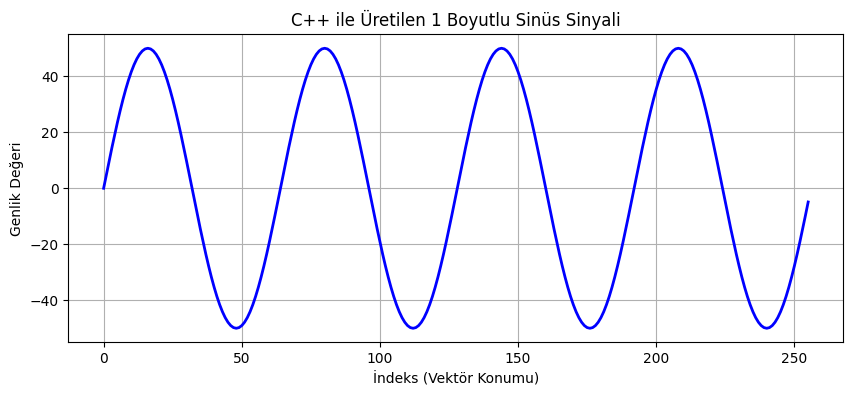

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# C++ programının oluşturduğu CSV dosyasını oku
df = pd.read_csv('sinyal_verisi.csv')

# Grafiği çizdir
plt.figure(figsize=(10, 4))
plt.plot(df['Index'], df['Value'], color='blue', linewidth=2)
plt.title('C++ ile Üretilen 1 Boyutlu Sinüs Sinyali')
plt.xlabel('İndeks (Vektör Konumu)')
plt.ylabel('Genlik Değeri')
plt.grid(True)
plt.show()